# MDST 3D Generative Pipeline — Week 6: From a Sentence to a City

## Goal

By the end of today, this one command works on **your** laptop:

```
python text2city/infer.py "a dense city in the hills with three business hubs" --preview
```

It prints the ten values your model predicts **and** the exact
`generate_city.py` command they turn into, runs it, and saves
`data/from_text.npz` plus a 2D preview. From there, Blender export is the
same step as Week 3.

```
"a dense city in the hills..."  ──►  your model  ──►  10 values  ──►  generate_city.py --terrain hills ...  ──►  city.npz  ──►  Blender
           (Week 5)                    (Week 5)                         (today: infer.py)                     (Week 2)       (Week 3)
```

## Plan (about 2 hours)

| Part | What | Time |
|---|---|---|
| 0 | Setup | 10 min |
| 1 | Same starting line: check your Week 5 files, retrain | 20 min |
| 2 | Write `infer.py` — the pipeline (TODO 1–3) | 45 min |
| 3 | Does the city match the sentence? (TODO 4–5) | 30 min |
| 4 | Blender export + gallery | 15 min |

### How this notebook works (same as before)

- **Run it top to bottom first, before writing anything.** Nothing crashes;
  checks print `[PASS]` / `[FAIL]` with a hint.
- Fill the `# <-- YOUR CODE HERE` lines, re-run that cell, then the check under it.
- **Keep every function name and argument as given** — the files call each other.


## Part 0 — Setup

In [1]:
import os, sys, subprocess, importlib, platform
from pathlib import Path

_here = Path.cwd().resolve()
for _c in [_here, *_here.parents]:
    if (_c / "citygen" / "city_grid.py").exists():
        os.chdir(_c); break
else:
    raise RuntimeError("Couldn't find the repo root (folder containing citygen/city_grid.py). "
                       "Put this notebook inside your project folder and restart the kernel.")

REPO = Path.cwd()
if str(REPO) not in sys.path:
    sys.path.insert(0, str(REPO))
(REPO / "text2city").mkdir(exist_ok=True)
(REPO / "data").mkdir(exist_ok=True)
print("repo root:", REPO)

repo root: C:\Users\ecw31\Desktop\Generative-3D-Cities


In [2]:
def check(label, condition, hint=""):
    """Reports PASS/FAIL. Never raises -- a failure should never stop you."""
    print(f"[{'PASS' if condition else 'FAIL'}] {label}")
    if not condition and hint:
        for line in hint.strip().splitlines():
            print(f"       {line}")
    return bool(condition)


def fresh(module_name):
    """
    Import a text2city module from disk, throwing away any copy Python
    cached earlier -- so a check always sees the file you JUST saved.
    Returns None (and says why) if the file won't import.
    """
    for name in list(sys.modules):
        if name == "text2city" or name.startswith("text2city.") or name == "generate_city":
            del sys.modules[name]
    try:
        return importlib.import_module(module_name)
    except BaseException as e:
        print(f"[FAIL] couldn't import {module_name}: {type(e).__name__}: {e}")
        return None


def run(args, timeout=1800, cwd=None):
    """Run a command (from the repo root unless cwd is given), printing output live. Returns (ok, output)."""
    print("$", " ".join(str(a) for a in args), "\n")
    p = subprocess.Popen([str(a) for a in args], cwd=cwd or REPO, stdout=subprocess.PIPE,
                         stderr=subprocess.STDOUT, text=True)
    lines = []
    for line in p.stdout:
        print(line, end="")
        lines.append(line)
    p.wait(timeout=timeout)
    out = "".join(lines)
    return (p.returncode == 0 and "Traceback" not in out), out

print("helpers ready")

helpers ready


### ML packages

If you did Week 5 on this laptop, this cell sees the packages and skips.
If you missed it, it installs them (pinned versions on an Intel Mac,
same as last week). That takes a few minutes.

In [3]:
have = subprocess.run([sys.executable, "-c", "import torch, sklearn, sentence_transformers"],
                      capture_output=True).returncode == 0
if have:
    print("torch, scikit-learn and sentence-transformers already installed -- nothing to do")
else:
    if platform.system() == "Darwin" and platform.machine() == "x86_64":
        print("Intel Mac detected -> installing pinned versions")
        steps = [
            ["install", "torch", "scikit-learn", "numpy<2"],
            ["uninstall", "-y", "sentence-transformers", "transformers", "huggingface-hub", "tokenizers", "safetensors"],
            ["install", "sentence-transformers==2.2.2", "transformers==4.30.2", "huggingface-hub==0.16.4"],
        ]
    else:
        steps = [["install", "torch", "scikit-learn", "sentence-transformers"]]
    for step in steps:
        r = subprocess.run([sys.executable, "-m", "pip", "-q", *step], capture_output=True, text=True)
        print(("ok   " if r.returncode == 0 else "FAIL ") + " ".join(step))
        if r.returncode != 0:
            print(r.stderr[-1500:])
    print("\nDone. Kernel > Restart, then run Part 0 again from the top.")

torch, scikit-learn and sentence-transformers already installed -- nothing to do


In [4]:
ok, out = run([sys.executable, "-c",
    "from sentence_transformers import SentenceTransformer; "
    "m = SentenceTransformer('all-MiniLM-L6-v2'); "
    "print('embedding shape:', m.encode(['a city by the sea']).shape)"])
check("sentence-transformer loads and embeds a sentence", ok and "(1, 384)" in out,
      "Read the error above. Intel Mac and 'Disabling PyTorch'? The pins didn't apply -- re-run\n"
      "the install cell, restart the kernel. Still stuck: ask an instructor.")

EMBEDDER = "sentence-transformer"   # leave this unless an instructor says otherwise

$ c:\Users\ecw31\Desktop\Generative-3D-Cities\.venv\Scripts\python.exe -c from sentence_transformers import SentenceTransformer; m = SentenceTransformer('all-MiniLM-L6-v2'); print('embedding shape:', m.encode(['a city by the sea']).shape) 


Loading weights: 100%|â–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆ| 103/103 [00:00<00:00, 2310.48it/s]
embedding shape: (1, 384)
[PASS] sentence-transformer loads and embeds a sentence


---

## Part 1 — Same starting line

Everyone needs a working Week 5 before we build on it.

### 1a. The given files (updated this week)

Run these four. They're the given files from Week 5 with two fixes:

- **`schema.py`**: when a sentence says *polycentric* but gives no number
  (*"a city with several business districts"*), `num_clusters` stays at its
  default of 1, and the generator would build **one** randomly placed hub.
  `to_generator_kwargs()` now uses 3 clusters in that case. Find
  `POLYCENTRIC_DEFAULT_CLUSTERS`.
- **`freshness.py`**: the checkpoint fingerprint now includes your citygen's
  terrain and city choices. Add a terrain to `terrain.py` and the model's
  terrain head no longer fits, so the checkpoint counts as **stale**. It
  also gained `is_stale()`, which `infer.py` uses.

Both change the fingerprint, so **everyone retrains today** (1c). That's on purpose.

In [5]:
%%writefile text2city/__init__.py
"""text2city: plain-English description -> citygen parameters."""


Overwriting text2city/__init__.py


In [6]:
%%writefile text2city/schema.py
"""
Single source of truth for the 10 city-generator parameters the
text-to-parameter model predicts.

Every other piece (dataset generation, model, training, evaluation, and the
inference script in a later week) imports PARAM_SCHEMA from here instead of
hardcoding parameter names or ranges. If the generator's parameters ever
change, this is the one file to update.

Each parameter is one of three kinds:
    categorical -- a fixed set of named choices (e.g. terrain archetype)
    continuous  -- a float in [low, high]
    binary      -- True/False

`default` is what the model should predict when a parameter is NOT
mentioned in the text at all (see generate_dataset.py). That keeps the
model predictable on short, partial prompts instead of guessing wildly
for anything the user didn't specify.

Terrain choices come from YOUR citygen package, not a fixed list: if your
terrain.py only implements flat and hills, the model only ever learns to
predict flat and hills -- so it can never hand the generator a terrain
type your code doesn't have.
"""
from __future__ import annotations

import sys
from dataclasses import dataclass
from pathlib import Path
from typing import Optional

sys.path.insert(0, str(Path(__file__).resolve().parent.parent))

try:
    from citygen import TERRAIN_ARCHETYPES, CITY_ARCHETYPES  # noqa: E402
except ImportError as exc:
    raise ImportError(
        "text2city needs your citygen package (terrain.py and buildings.py) to "
        "import cleanly, because the model learns exactly the terrain and city "
        f"types you implemented. Original error: {exc}"
    ) from exc


@dataclass
class ParamSpec:
    name: str
    kind: str  # "categorical" | "continuous" | "binary"
    default: object
    choices: Optional[list] = None       # required for "categorical"
    value_range: Optional[tuple] = None  # required for "continuous", (low, high)
    # how often a synthetic training sentence mentions this parameter at all
    mention_prob: float = 0.35


_TERRAINS = list(TERRAIN_ARCHETYPES)
_TERRAIN_DEFAULT = "hills" if "hills" in _TERRAINS else _TERRAINS[0]
_CITIES = list(CITY_ARCHETYPES)
_CITY_DEFAULT = "monocentric" if "monocentric" in _CITIES else _CITIES[0]


PARAM_SCHEMA: list[ParamSpec] = [
    ParamSpec(
        name="terrain", kind="categorical", default=_TERRAIN_DEFAULT,
        choices=_TERRAINS,
        mention_prob=0.8,
    ),
    ParamSpec(
        name="city_archetype", kind="categorical", default=_CITY_DEFAULT,
        choices=_CITIES,
        mention_prob=0.65,
    ),
    ParamSpec(
        name="num_clusters", kind="continuous", default=1.0,
        value_range=(1.0, 6.0),
        mention_prob=0.25,
    ),
    ParamSpec(
        name="density", kind="continuous", default=0.5,
        value_range=(0.0, 1.0),
        mention_prob=0.55,
    ),
    ParamSpec(
        name="cluster_tightness", kind="continuous", default=0.5,
        value_range=(0.0, 1.0),
        mention_prob=0.3,
    ),
    ParamSpec(
        name="relief", kind="continuous", default=1.0,
        value_range=(0.0, 2.0),
        mention_prob=0.3,
    ),
    ParamSpec(
        name="water_level", kind="continuous", default=0.2,
        value_range=(0.0, 0.6),
        mention_prob=0.3,
    ),
    ParamSpec(
        name="green_amount", kind="continuous", default=0.15,
        value_range=(0.0, 1.0),
        mention_prob=0.45,
    ),
    ParamSpec(
        name="green_override", kind="binary", default=False,
        mention_prob=0.1,
    ),
    ParamSpec(
        name="road_continuity", kind="continuous", default=0.7,
        value_range=(0.0, 1.0),
        mention_prob=0.25,
    ),
]

PARAM_NAMES = [p.name for p in PARAM_SCHEMA]
PARAM_BY_NAME = {p.name: p for p in PARAM_SCHEMA}

CATEGORICAL_PARAMS = [p for p in PARAM_SCHEMA if p.kind == "categorical"]
CONTINUOUS_PARAMS = [p for p in PARAM_SCHEMA if p.kind == "continuous"]
BINARY_PARAMS = [p for p in PARAM_SCHEMA if p.kind == "binary"]


def default_vector() -> dict:
    """The full parameter dict when nothing at all is mentioned."""
    return {p.name: p.default for p in PARAM_SCHEMA}


# cluster count used when the text says polycentric but gives no number
POLYCENTRIC_DEFAULT_CLUSTERS = 3


def to_generator_kwargs(params: dict) -> dict:
    """
    Map this schema's parameter names onto generate_city.py's build_city()
    keyword arguments.

    water_level needs special handling: the model always predicts SOME
    number for it, but generate_terrain()'s own default depends on the
    archetype (land-locked ones default to no water at all). So if the
    prediction sits near the schema default -- meaning the text probably
    said nothing about water -- pass None and let generate_terrain() pick
    the right per-archetype default. Otherwise an unmentioned water level
    can flood a third of a mountain map.
    """
    water_level = params["water_level"]
    water_spec = PARAM_BY_NAME["water_level"]
    water_level_kwarg = None if abs(water_level - water_spec.default) < 0.03 else water_level

    # A polycentric city needs at least two centers, but "a city with several
    # business districts" gives no number, so num_clusters keeps its default
    # of 1 -- and the generator would build ONE randomly placed hub. When the
    # text didn't say how many, use a sensible polycentric count instead.
    clusters = int(round(params["num_clusters"]))
    if params["city_archetype"] == "polycentric" and clusters < 2:
        clusters = POLYCENTRIC_DEFAULT_CLUSTERS

    return {
        "terrain_archetype": params["terrain"],
        "city_archetype": params["city_archetype"],
        "clusters": clusters,
        "density": params["density"],
        "cluster_tightness": params["cluster_tightness"],
        "relief": params["relief"],
        "water_level": water_level_kwarg,
        "green_amount": params["green_amount"],
        "green_override": bool(params["green_override"]),
        "road_continuity": params["road_continuity"],
    }


Overwriting text2city/schema.py


In [7]:
%%writefile text2city/embedders.py
"""
Sentence-embedding backends -- turn a list of sentences into a fixed-size
float array. Same interface for both: fit() on the training texts (a no-op
for the pretrained one), then encode() any list of strings.

  "sentence-transformer" (what we use): all-MiniLM-L6-v2, a pretrained
      model that already understands English. It places "surrounded by
      peaks" close to "surrounded by mountains" even though only one of
      them is in our dataset. Needs `sentence-transformers` and a one-time
      ~80MB download (cached, offline afterwards). It is FROZEN: we never
      train it, only the small model on top.

  "tfidf" (offline fallback): classic word counts. Only knows words it saw
      while fitting, so it can't handle a synonym it never met -- but it
      needs no download, which makes it a useful backup.
"""
from __future__ import annotations

import pickle

import numpy as np


class TfidfEmbedder:
    kind = "tfidf"

    def __init__(self, max_features: int = 1200):
        from sklearn.feature_extraction.text import TfidfVectorizer
        self.vectorizer = TfidfVectorizer(max_features=max_features, ngram_range=(1, 2))
        self._fitted = False

    def fit(self, texts: list[str]):
        self.vectorizer.fit(texts)
        self._fitted = True
        return self

    def encode(self, texts: list[str]) -> np.ndarray:
        if not self._fitted:
            raise RuntimeError("TfidfEmbedder.fit() must be called before encode()")
        return self.vectorizer.transform(texts).toarray().astype(np.float32)

    def save(self, path: str):
        with open(path, "wb") as f:
            pickle.dump(self.vectorizer, f)

    @classmethod
    def load(cls, path: str) -> "TfidfEmbedder":
        obj = cls.__new__(cls)
        with open(path, "rb") as f:
            obj.vectorizer = pickle.load(f)
        obj._fitted = True
        return obj


class SentenceTransformerEmbedder:
    kind = "sentence-transformer"

    def __init__(self, model_name: str = "all-MiniLM-L6-v2"):
        from sentence_transformers import SentenceTransformer
        self.model = SentenceTransformer(model_name)
        self.model_name = model_name

    def fit(self, texts: list[str]):
        return self  # pretrained and frozen -- nothing to fit

    def encode(self, texts: list[str]) -> np.ndarray:
        return np.asarray(self.model.encode(texts, convert_to_numpy=True), dtype=np.float32)

    def save(self, path: str):
        # nothing to save but the name -- the weights live in the download cache
        with open(path, "w") as f:
            f.write(self.model_name)

    @classmethod
    def load(cls, path: str) -> "SentenceTransformerEmbedder":
        with open(path) as f:
            return cls(f.read().strip())


def get_embedder(kind: str, **kwargs):
    if kind == "tfidf":
        return TfidfEmbedder(**kwargs)
    if kind == "sentence-transformer":
        return SentenceTransformerEmbedder(**kwargs)
    raise ValueError(f"unknown embedder kind {kind!r}, choose 'tfidf' or 'sentence-transformer'")


def embedder_filename(kind: str) -> str:
    return "embedder.pkl" if kind == "tfidf" else "embedder.txt"


def load_embedder(kind: str, path: str):
    if kind == "tfidf":
        return TfidfEmbedder.load(path)
    if kind == "sentence-transformer":
        return SentenceTransformerEmbedder.load(path)
    raise ValueError(f"unknown embedder kind {kind!r}")


Overwriting text2city/embedders.py


In [8]:
%%writefile text2city/freshness.py
"""
Staleness detection for checkpoints.

Editing generate_dataset.py, schema.py, dataset.py or model.py does NOTHING
to a checkpoint that's already trained -- you have to re-run
generate_dataset.py and train.py for the change to count. It's easy to
forget, and then you spend an hour asking why your fix doesn't work.

train.py stores a fingerprint of the dataset CSV, those source files and the terrain / city
choices in the checkpoint. evaluate.py recomputes it and warns loudly if they differ.
"""
from __future__ import annotations

import hashlib
from pathlib import Path

SOURCE_FILES = ["schema.py", "generate_dataset.py", "dataset.py", "model.py"]


def fingerprint_sources(dataset_path: str) -> str:
    hasher = hashlib.sha256()
    dataset_file = Path(dataset_path)
    hasher.update(dataset_file.read_bytes() if dataset_file.exists() else b"MISSING_DATASET")
    here = Path(__file__).resolve().parent
    for name in SOURCE_FILES:
        path = here / name
        if path.exists():
            hasher.update(path.read_bytes())
    # The terrain and city choices come from YOUR citygen, not from text2city.
    # Add a terrain to terrain.py and the model's terrain head no longer
    # matches -- so the choices are part of the fingerprint too.
    from text2city.schema import PARAM_SCHEMA
    choices = [(p.name, list(p.choices)) for p in PARAM_SCHEMA if p.choices]
    hasher.update(repr(choices).encode())
    return hasher.hexdigest()[:16]


def is_stale(checkpoint_fingerprint, dataset_path: str) -> bool:
    """True if the checkpoint was trained on different data, code or terrains."""
    return checkpoint_fingerprint is None or fingerprint_sources(dataset_path) != checkpoint_fingerprint


def check_staleness(checkpoint_fingerprint, dataset_path: str) -> None:
    """Prints a loud warning (never raises) if the checkpoint looks stale."""
    if checkpoint_fingerprint is None:
        print("WARNING: checkpoint has no fingerprint (trained by an older train.py) -- consider retraining.")
        return
    if is_stale(checkpoint_fingerprint, dataset_path):
        print("=" * 70)
        print("WARNING: this checkpoint appears STALE.")
        print("The dataset CSV, schema.py / generate_dataset.py / dataset.py / model.py,")
        print("or your citygen terrain list changed since it was trained. Results below")
        print("reflect the OLD model.")
        print("Fix: re-run generate_dataset.py, then train.py.")
        print("=" * 70)


Overwriting text2city/freshness.py


### 1b. Progress check

This tests each of your five Week 5 files on its own and prints one line per
file. **If any line says anything but `ok`:** get the reference version of
those files from the GitHub repo, put them in `text2city/`, and re-run this
cell. (Want to keep yours? Rename it first, e.g. `model_mine.py`.)

In [9]:
import csv, re, tempfile
import numpy as np

STUB = re.compile(r"\.\.\.\s*:?\s*#\s*<-- YOUR CODE HERE")
MEMBER_FILES = ["generate_dataset.py", "dataset.py", "model.py", "train.py", "evaluate.py"]
status = {}


def _unfinished(name):
    lines = (REPO / "text2city" / name).read_text().splitlines()
    todo = [i + 1 for i, line in enumerate(lines) if STUB.search(line)]
    return f"unfinished TODO on line {todo[0]}" if todo else None


def _test_generate_dataset():
    gd = fresh("text2city.generate_dataset")
    if gd is None:
        return "doesn't import (error above)"
    rows = gd.generate_dataset(3000, seed=0)
    if len({r["text"] for r in rows}) < 1500:
        return "sentences aren't varied -- TODO 1-3 don't work yet"
    spec = gd.PARAM_BY_NAME["relief"]
    rate = np.mean([abs(r["relief"] - spec.default) > 1e-9 for r in rows])
    if abs(rate - spec.mention_prob) > 0.06:
        return f"relief is mentioned {rate:.0%} of the time, want ~{spec.mention_prob:.0%} (TODO 2)"
    tmp = Path(tempfile.mkdtemp()) / "rows.csv"
    with open(tmp, "w", newline="") as f:
        w = csv.DictWriter(f, fieldnames=["text"] + gd.PARAM_NAMES)
        w.writeheader(); w.writerows(rows)
    globals()["_SAMPLE_CSV"] = tmp


def _test_dataset():
    if "_SAMPLE_CSV" not in globals():
        return "not tested -- needs a working generate_dataset.py first"
    ds = fresh("text2city.dataset")
    if ds is None:
        return "doesn't import (error above)"
    rows = ds.load_rows(str(_SAMPLE_CSV))
    t = ds.build_targets(rows)
    for spec in ds.PARAM_SCHEMA:
        a = t.get(spec.name)
        if not isinstance(a, np.ndarray):
            return f"{spec.name} target isn't an array (TODO 4)"
        if spec.kind == "categorical" and a.dtype != np.int64:
            return f"{spec.name} should be int64 class indices (TODO 4a)"
        if spec.kind == "continuous" and not (a.dtype == np.float32 and a.min() >= -1e-6 and a.max() <= 1 + 1e-6):
            return f"{spec.name} should be float32 in [0, 1] (TODO 4b)"
        if spec.kind == "binary" and not set(np.unique(a)) <= {0.0, 1.0}:
            return f"{spec.name} should be 0.0 / 1.0 (TODO 4c)"


def _test_model():
    import torch
    mm = fresh("text2city.model")
    if mm is None:
        return "doesn't import (error above)"
    out = mm.TextToCityParams(embedding_dim=384, hidden_dim=32)(torch.randn(4, 384))
    for p in mm.PARAM_SCHEMA:
        want = (4, len(p.choices)) if p.kind == "categorical" else (4, 1)
        if not isinstance(out, dict) or tuple(out[p.name].shape) != want:
            return f"{p.name} head should output {want} (TODO 5-6)"


def _test_train():
    import torch
    if status.get("model.py") != "ok":
        return "not tested -- needs a working model.py first"
    tr = fresh("text2city.train")
    if tr is None:
        return "doesn't import (error above)"
    torch.manual_seed(0)
    model = tr.TextToCityParams(embedding_dim=384, hidden_dim=32)
    x = torch.randn(32, 384)
    fake = {}
    for p in tr.PARAM_SCHEMA:
        fake[p.name] = (np.random.randint(0, len(p.choices), 32).astype(np.int64) if p.kind == "categorical"
                        else np.random.rand(32).astype(np.float32))
    fake["green_override"] = (fake["green_override"] > 0.5).astype(np.float32)
    weights = {p.name: torch.ones(len(p.choices)) for p in tr.PARAM_SCHEMA if p.kind == "categorical"}
    opt = torch.optim.Adam(model.parameters(), lr=1e-2)
    first = tr.compute_loss(model(x), fake, weights).item()
    for _ in range(40):
        loss = tr.compute_loss(model(x), fake, weights)
        opt.zero_grad(); loss.backward(); opt.step()
    if not loss.item() < first * 0.7:
        return f"loss doesn't go down ({first:.2f} -> {loss.item():.2f}) (TODO 7)"


def _test_evaluate():
    if status.get("model.py") != "ok":
        return "not tested -- needs a working model.py first"
    ev = fresh("text2city.evaluate")
    if ev is None:
        return "doesn't import (error above)"
    if len(ev.HANDWRITTEN_EXAMPLES) < 9:
        return "needs at least 3 hand-written sentences of your own (TODO 10)"


TESTS = {"generate_dataset.py": _test_generate_dataset, "dataset.py": _test_dataset,
         "model.py": _test_model, "train.py": _test_train, "evaluate.py": _test_evaluate}

for name in MEMBER_FILES:
    if not (REPO / "text2city" / name).exists():
        status[name] = "MISSING"
        continue
    try:
        status[name] = _unfinished(name) or TESTS[name]() or "ok"
    except BaseException as e:
        status[name] = f"crashes: {type(e).__name__}: {e}"

ok_city, out_city = run([sys.executable, "scripts/generate_city.py", "--size", "32", "--seed", "0",
                         "--out", "data/_check_city.npz"])
status["citygen + generate_city.py"] = "ok" if ok_city else "fails -- see the output above (Week 4 checklist)"

print("\n" + "=" * 64)
for name, s in status.items():
    print(f"  {name:28s} {s}")
print("=" * 64)
broken = [n for n, s in status.items() if s != "ok" and not s.startswith("not tested")]
untested = [n for n, s in status.items() if s.startswith("not tested")]
check("every Week 5 file works", not broken and not untested,
      ("Get the reference copy of: " + ", ".join(broken) + "\n"
       "from the GitHub repo, put it in text2city/, then re-run this cell." if broken else "") +
      ("\nThen re-run this cell to test: " + ", ".join(untested) if untested else ""))
if (REPO / "text2city" / "_internal_mechanics_test.py").exists():
    print("\nNOTE: delete text2city/_internal_mechanics_test.py -- it's an instructor test file.")

$ c:\Users\ecw31\Desktop\Generative-3D-Cities\.venv\Scripts\python.exe scripts/generate_city.py --size 32 --seed 0 --out data/_check_city.npz 

saved data/_check_city.npz
  size: 32
  water_pct: 0.00
  building_pct: 15.33
  green_pct: 6.74
  road_pct: 36.23
  max_building_height: 7.34
  mean_building_height: 3.01

  generate_dataset.py          ok
  dataset.py                   ok
  model.py                     ok
  train.py                     ok
  evaluate.py                  ok
  citygen + generate_city.py   ok
[PASS] every Week 5 file works


### 1c. Rebuild the dataset and retrain

The dataset, then your model, from **your** current files, so the
checkpoint is fresh. About a minute or two; the epoch lines show progress.

In [10]:
ok_gen, _ = run([sys.executable, "text2city/generate_dataset.py", "--n", "15000", "--seed", "0"])
check("dataset rebuilt", ok_gen and (REPO / "data" / "text2city_dataset.csv").exists())

ok_train, out_train = run([sys.executable, "text2city/train.py", "--embedder", EMBEDDER])
check("model retrained", ok_train and "saved checkpoint" in out_train, "Read the traceback above.")

$ c:\Users\ecw31\Desktop\Generative-3D-Cities\.venv\Scripts\python.exe text2city/generate_dataset.py --n 15000 --seed 0 

wrote 15000 examples to data\text2city_dataset.csv

sample rows:
  I'd like a city with medium density, on hilly terrain, and with almost no greenery.
    -> {'terrain': 'hills', 'city_archetype': 'monocentric', 'num_clusters': 1.0, 'density': 0.59, 'cluster_tightness': 0.5, 'relief': 1.0, 'water_level': 0.2, 'green_amount': 0.09, 'green_override': False, 'road_continuity': 0.7}
  Generate a city highly concentrated, with gently varying elevation, on level ground, with one clear city center, and with a single center.
    -> {'terrain': 'flat', 'city_archetype': 'monocentric', 'num_clusters': 1.09, 'density': 0.85, 'cluster_tightness': 0.5, 'relief': 0.86, 'water_level': 0.2, 'green_amount': 0.15, 'green_override': False, 'road_continuity': 0.7}
  Design a city with barely any water, this city is linear, and on hilly terrain.
    -> {'terrain': 'hills', 'city_archety

True

In [11]:
ok_eval, out_eval = run([sys.executable, "text2city/evaluate.py"])
check("evaluate.py runs on the fresh checkpoint", ok_eval and "STALE" not in out_eval,
      "STALE? Re-run the cell above. A traceback? Your evaluate.py -- see 1b.")

$ c:\Users\ecw31\Desktop\Generative-3D-Cities\.venv\Scripts\python.exe text2city/evaluate.py 


Loading weights: 100%|â–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆ| 103/103 [00:00<00:00, 1678.88it/s]
=== 1. held-out synthetic examples ===
  terrain              accuracy = 1.000
  city_archetype       accuracy = 0.960
  num_clusters         MAE      = 0.1340
  density              MAE      = 0.0757
  cluster_tightness    MAE      = 0.0582
  relief               MAE      = 0.0921
  water_level          MAE      = 0.0297
  green_amount         MAE      = 0.0569
  green_override       accuracy = 1.000
  road_continuity      MAE      = 0.0379

=== 2. hand-written sentences (the generalisation test) ===

  "a huge sprawling metropolis packed with skyscrapers"
      PASS  density              wanted 'high'         got 0.93

  "a quiet little town on flat land with hardly any buildings"
      PASS  terrain              wanted 'flat'         got 'flat'
      PASS  density              wanted 'low'          go

True

---

## Part 2 — The pipeline: `infer.py`

### The design: the command line is the hand-off

`infer.py` never reaches into the generator. It turns the model's
prediction into an ordinary **`generate_city.py` command**, prints it, and
runs it. Why go through the command line?

- It's the command you've run since Week 2, nothing new to learn.
- **The printed command is a receipt.** Copy it, change `--density`, run it
  again. If a city looks wrong, you can tell *which half* is wrong: if the
  numbers are wrong, the model is to blame; if the numbers are right but the
  city isn't, the generator is.
- `generate_city.py` already rejects a terrain your citygen doesn't have.

The conversion happens in two steps:

```
predicted params           to_generator_kwargs()          kwargs_to_cli_args()
{"terrain": "hills",   ──►  {"terrain_archetype": "hills",  ──►  ["--terrain", "hills",
 "num_clusters": 2.8,        "clusters": 3,                       "--clusters", "3",
 "water_level": 0.21,        "water_level": None,                 (left out)
 "green_override": False}    "green_override": False}             (left out)
                            (given, schema.py)                   (you, TODO 2)
```

First, look at what `generate_city.py` expects. Every rule in TODO 2 comes
from this help text:

In [12]:
ok, _ = run([sys.executable, "scripts/generate_city.py", "--help"])

$ c:\Users\ecw31\Desktop\Generative-3D-Cities\.venv\Scripts\python.exe scripts/generate_city.py --help 

usage: generate_city.py [-h] [--size SIZE] [--terrain {flat,hills}]
                        [--city {monocentric,polycentric,linear}]
                        [--clusters CLUSTERS] [--density DENSITY]
                        [--cluster-tightness CLUSTER_TIGHTNESS]
                        [--relief RELIEF] [--water-level WATER_LEVEL]
                        [--green-amount GREEN_AMOUNT] [--green-override]
                        [--road-continuity ROAD_CONTINUITY] [--seed SEED]
                        [--out OUT]

Generate one synthetic city and save it as a .npz CityGrid. Example: python
scripts/generate_city.py \ --size 128 --terrain coastal_harbor --city
polycentric \ --clusters 3 --density 0.6 --cluster-tightness 0.6 \ --green-
amount 0.3 --road-continuity 0.65 \ --seed 42 --out data/city_harbor.npz

options:
  -h, --help            show this help message and exit
  --size SIZE
  

Now write `infer.py`: **TODO 1** (predict one sentence), **TODO 2**
(keyword arguments → flags), **TODO 3** (the full command). Everything
else is given; skim `main()` to see how it fits together.

In [39]:
%%writefile text2city/infer.py
#!/usr/bin/env python3
"""
Week 6: a plain-English sentence -> the 10 parameters -> a generated city.

    python text2city/infer.py "a dense city in the hills with three business hubs" --preview
    python text2city/infer.py "a quiet town on flat land" --dry-run    # print the command only

The model never calls the generator itself. infer.py turns its prediction
into an ordinary generate_city.py command -- the one you've run since
Week 2 -- prints it, and runs it. The printed command is the hand-off
point: copy it, change a number, run it again yourself.
"""
import argparse
import random
import shlex
import subprocess
import sys
from pathlib import Path

# Every path is worked out from this file's own location, so infer.py works
# no matter which folder you run it from.
ROOT = Path(__file__).resolve().parent.parent
sys.path.insert(0, str(ROOT))

from text2city.schema import to_generator_kwargs  # noqa: E402

GENERATE_CITY = ROOT / "scripts" / "generate_city.py"
VISUALIZE_2D = ROOT / "scripts" / "visualize_2d.py"
DEFAULT_CHECKPOINT = ROOT / "text2city" / "checkpoint"
DEFAULT_DATASET = ROOT / "data" / "text2city_dataset.csv"
DEFAULT_OUT = ROOT / "data" / "from_text.npz"

# build_city() keyword arguments whose generate_city.py flag doesn't follow
# the usual rule. Every other flag is "--" + the name with "_" turned into "-".
SPECIAL_FLAGS = {"terrain_archetype": "--terrain", "city_archetype": "--city"}


def predict_params(text, checkpoint_dir=DEFAULT_CHECKPOINT, dataset_path=DEFAULT_DATASET,
                   allow_stale=False) -> dict:
    """One sentence -> {parameter name: predicted value}, floats rounded to 3 decimals."""
    # imported here rather than at the top: torch takes a few seconds to load,
    # and `infer.py --help` shouldn't have to wait for it
    import torch
    from text2city.evaluate import load_checkpoint, predict
    from text2city.freshness import is_stale

    ckpt_file = Path(checkpoint_dir) / "model.pt"
    if not ckpt_file.exists():
        sys.exit(f"No checkpoint at {ckpt_file}. Train one first:  python text2city/train.py")
    fingerprint = torch.load(ckpt_file, map_location="cpu", weights_only=False).get("fingerprint")
    if is_stale(fingerprint, str(dataset_path)) and not allow_stale:
        sys.exit("This checkpoint is STALE: your dataset, text2city code or citygen terrains\n"
                 "changed after it was trained, so its predictions belong to the old setup.\n"
                 "Fix:  python text2city/generate_dataset.py   then   python text2city/train.py\n"
                 "(or pass --allow-stale to use it anyway)")

    # TODO 1: load the trained model and predict this ONE sentence.
    # evaluate.py already has both functions (imported at the top of this function):
    #   load_checkpoint(checkpoint_dir, dataset_path) -> (model, embedder)
    #       pass both paths through str() -- they may arrive as Path objects
    #   predict(model, embedder, list_of_texts) -> a LIST with one dict per text
    model, embedder = load_checkpoint(str(checkpoint_dir), str(dataset_path))  # <-- YOUR CODE HERE
    params = predict(model, embedder, [text])[0]           # <-- YOUR CODE HERE

    return {k: round(v, 3) if isinstance(v, float) else v for k, v in params.items()}


def kwargs_to_cli_args(kwargs: dict) -> list:
    """
    build_city() keyword arguments -> generate_city.py command-line arguments.

        {"terrain_archetype": "hills", "clusters": 3, "density": 0.81,
         "water_level": None, "green_override": False}
     -> ["--terrain", "hills", "--clusters", "3", "--density", "0.81"]

    The rules come from how generate_city.py declares its arguments
    (run `python scripts/generate_city.py --help` to see them):
        flag name      SPECIAL_FLAGS if listed there, otherwise
                       "--" + the name with "_" replaced by "-"
        None           leave the flag out -- generate_city.py then uses its
                       own default (water level depends on the terrain)
        True           the flag on its own, no value: --green-override is a
                       switch, it's either there or it isn't
        False          leave it out
        anything else  the flag, then str(value)
    """
    args = []
    for name, value in kwargs.items():
        # TODO 2a: the flag for this keyword argument.
        # Hint: SPECIAL_FLAGS.get(name, fallback) returns fallback when name isn't listed.
        flag = SPECIAL_FLAGS.get(name, "--" + name.replace("_", "-"))  # <-- YOUR CODE HERE

        # TODO 2b: add to `args`, following the four rules in the docstring.
        # Test with `value is None`, `value is True`, `value is False` -- NOT ==.
        # In Python 1 == True and 0.0 == False, so == would turn "--clusters 1"
        # into a bare switch and silently drop "--density 0.0".
        if value is None:
            continue
        elif value is True:
            args.append(flag)
        elif value is False:
            continue
        else:
            args.extend([flag, str(value)])
    return args


def build_command(params: dict, size: int, seed: int, out) -> list:
    """The full generate_city.py command for one set of predicted parameters."""
    # TODO 3: chain the two conversions, then assemble the full command.
    #   params --to_generator_kwargs()--> build_city() keyword arguments
    #          --kwargs_to_cli_args()-->  ["--terrain", "hills", ...]
    # The command is a list of STRINGS, in this order:
    #   sys.executable (the Python running right now), str(GENERATE_CITY),
    #   the args from above, then "--size", "--seed" and "--out", each followed by its value
    kwargs = to_generator_kwargs(params)
    cli_args = kwargs_to_cli_args(kwargs)

    return [
        sys.executable,
        str(GENERATE_CITY),
        *cli_args,
        "--size", str(size),
        "--seed", str(seed),
        "--out", str(out),
    ]


def display_command(cmd: list) -> str:
    """cmd as you'd type it from the repo root: `python scripts/...`, short paths."""
    shown = ["python"]
    for part in cmd[1:]:
        path = Path(part)
        if path.is_absolute() and ROOT in path.parents:
            part = str(path.relative_to(ROOT))
        shown.append(part)
    return shlex.join(shown)


def main():
    parser = argparse.ArgumentParser(description=__doc__, formatter_class=argparse.RawDescriptionHelpFormatter)
    parser.add_argument("text", type=str, help="describe the city, in quotes")
    parser.add_argument("--checkpoint", type=str, default=str(DEFAULT_CHECKPOINT))
    parser.add_argument("--dataset", type=str, default=str(DEFAULT_DATASET))
    parser.add_argument("--size", type=int, default=128)
    parser.add_argument("--seed", type=int, default=None, help="same seed + same sentence = same city")
    parser.add_argument("--out", type=str, default=str(DEFAULT_OUT))
    parser.add_argument("--preview", action="store_true", help="also save a 2D PNG next to the .npz")
    parser.add_argument("--dry-run", action="store_true", help="print the command, don't run it")
    parser.add_argument("--allow-stale", action="store_true", help="use a stale checkpoint anyway")
    args = parser.parse_args()

    params = predict_params(args.text, args.checkpoint, args.dataset, args.allow_stale)
    print(f'"{args.text}"\n\npredicted parameters:')
    for name, value in params.items():
        print(f"  {name:20s} = {value}")

    # Always pass a seed -- if you didn't choose one, pick one -- so the
    # printed command rebuilds exactly this city when you run it again.
    seed = args.seed if args.seed is not None else random.randrange(10_000)
    out = Path(args.out).resolve()
    cmd = build_command(params, args.size, seed, out)
    print("\ngenerate_city.py command:\n  " + display_command(cmd))
    if args.dry_run:
        return

    print()
    result = subprocess.run(cmd, cwd=ROOT)
    if result.returncode != 0 or not out.exists():
        sys.exit("generate_city.py failed -- read its error above.")

    if args.preview:
        png = out.with_suffix(".png")
        subprocess.run([sys.executable, str(VISUALIZE_2D), str(out), "--out", str(png)], cwd=ROOT, check=True)
        print(f"preview: {png}")


if __name__ == "__main__":
    main()


Overwriting text2city/infer.py


### Check TODO 1: predict one sentence

In [30]:
inf = fresh("text2city.infer")
if inf:
    schema = importlib.import_module("text2city.schema")
    try:
        p = inf.predict_params("a dense city in the hills with three business hubs")
        check("TODO 1: one value for each of the 10 parameters",
              isinstance(p, dict) and set(p) == set(schema.PARAM_NAMES),
              f"got {type(p).__name__}: {p!r:.200}\npredict() returns a LIST of dicts -- take element [0].")
        if isinstance(p, dict) and set(p) == set(schema.PARAM_NAMES):
            ok = all((v in s.choices) if s.kind == "categorical" else
                     (s.value_range[0] - 1e-6 <= v <= s.value_range[1] + 1e-6) if s.kind == "continuous" else
                     isinstance(v, bool) for s, v in ((schema.PARAM_BY_NAME[k], v) for k, v in p.items()))
            check("TODO 1: every value is a valid choice / inside its range", ok, f"{p}")
            for k, v in p.items():
                print(f"   {k:20s} = {v}")
    except BaseException as e:
        check("TODO 1 runs", False, f"{type(e).__name__}: {e}")

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 2083.78it/s]


[PASS] TODO 1: one value for each of the 10 parameters
[PASS] TODO 1: every value is a valid choice / inside its range
   terrain              = hills
   city_archetype       = polycentric
   num_clusters         = 1.759
   density              = 0.574
   cluster_tightness    = 0.523
   relief               = 1.143
   water_level          = 0.208
   green_amount         = 0.172
   green_override       = False
   road_continuity      = 0.713


### Check TODO 2: keyword arguments → flags

In [35]:
inf = fresh("text2city.infer")
CASES = [
    ("renamed flags",        {"terrain_archetype": "hills", "city_archetype": "linear"}, ["--terrain", "hills", "--city", "linear"]),
    ("numbers",              {"clusters": 3, "density": 0.812}, ["--clusters", "3", "--density", "0.812"]),
    ("_ becomes -",          {"cluster_tightness": 0.5, "road_continuity": 0.7}, ["--cluster-tightness", "0.5", "--road-continuity", "0.7"]),
    ("None is left out",     {"water_level": None, "density": 0.5}, ["--density", "0.5"]),
    ("a real water level",   {"water_level": 0.4}, ["--water-level", "0.4"]),
    ("True is a bare switch", {"green_override": True}, ["--green-override"]),
    ("False is left out",    {"green_override": False, "clusters": 2}, ["--clusters", "2"]),
    ("1 and 0.0 are numbers, not True/False", {"clusters": 1, "density": 0.0}, ["--clusters", "1", "--density", "0.0"]),
]
if inf:
    for label, kwargs, want in CASES:
        try:
            got = inf.kwargs_to_cli_args(kwargs)
            check(f"TODO 2: {label}", got == want, f"kwargs {kwargs}\n  want {want}\n  got  {got}")
        except BaseException as e:
            check(f"TODO 2: {label}", False, f"{type(e).__name__}: {e}")

[PASS] TODO 2: renamed flags
[PASS] TODO 2: numbers
[PASS] TODO 2: _ becomes -
[PASS] TODO 2: None is left out
[PASS] TODO 2: a real water level
[PASS] TODO 2: True is a bare switch
[PASS] TODO 2: False is left out
[PASS] TODO 2: 1 and 0.0 are numbers, not True/False


### Check TODO 3, then the real test

`SAMPLE` is a hand-made prediction, so this works even if TODO 1 doesn't.
The last check builds the **same** city two ways with the same seed:

1. through **your** command, the way `infer.py` will do it
2. directly, `build_city(**to_generator_kwargs(SAMPLE))`, skipping the command line

If your conversion is right, the two grids are **identical**, cell for cell.
A misspelled flag, a dropped value or a wrong default shows up here.

In [40]:
inf = fresh("text2city.infer")
if inf:
    schema = importlib.import_module("text2city.schema")
    terrains = schema.PARAM_BY_NAME["terrain"].choices
    cities = schema.PARAM_BY_NAME["city_archetype"].choices
    SAMPLE = {"terrain": "hills" if "hills" in terrains else terrains[0],
              "city_archetype": "polycentric" if "polycentric" in cities else cities[0],
              "num_clusters": 1.2, "density": 0.65, "cluster_tightness": 0.4, "relief": 1.3,
              "water_level": 0.35, "green_amount": 0.3, "green_override": False, "road_continuity": 0.55}
    CLI_NPZ = REPO / "data" / "_cli_city.npz"
    try:
        cmd = inf.build_command(SAMPLE, 64, 7, CLI_NPZ)
        check("TODO 3: a list of strings", isinstance(cmd, list) and all(isinstance(c, str) for c in cmd),
              f"got {cmd!r:.300}\nWrap numbers and paths in str().")
        if isinstance(cmd, list) and len(cmd) > 2:
            check("TODO 3: starts with this Python, then generate_city.py",
                  cmd[0] == sys.executable and Path(cmd[1]).name == "generate_city.py" and Path(cmd[1]).exists(),
                  f"got {cmd[:2]}")
            check("TODO 3: has --size 64, --seed 7 and --out",
                  all(x in cmd for x in ("--size", "64", "--seed", "7", "--out")), f"got {cmd}")
            check("TODO 3: polycentric with 1 cluster becomes --clusters 3",
                  "--clusters" in cmd and cmd[cmd.index("--clusters") + 1] == "3",
                  "Did you pass params through to_generator_kwargs() first?")
            print("\n" + inf.display_command(cmd) + "\n")

            CLI_NPZ.unlink(missing_ok=True)
            r = subprocess.run(cmd, cwd=REPO, capture_output=True, text=True)
            check("generate_city.py accepts your command", r.returncode == 0 and CLI_NPZ.exists(),
                  (r.stderr or r.stdout)[-800:])
            if CLI_NPZ.exists():
                sys.path.insert(0, str(REPO / "scripts"))
                from generate_city import build_city
                direct = build_city(size=64, seed=7, **schema.to_generator_kwargs(SAMPLE))
                saved = np.load(CLI_NPZ)
                same = all(np.array_equal(saved[k], getattr(direct, k))
                           for k in ("terrain_height", "is_water", "building_height", "land_use"))
                check("command-line city == direct build_city() city, cell for cell", same,
                      "Your command built a DIFFERENT city. Compare the command above with\n"
                      "to_generator_kwargs(SAMPLE) -- which value didn't make it through?")
    except BaseException as e:
        check("TODO 3 runs", False, f"{type(e).__name__}: {e}")

[PASS] TODO 3: a list of strings
[PASS] TODO 3: starts with this Python, then generate_city.py
[PASS] TODO 3: has --size 64, --seed 7 and --out
[PASS] TODO 3: polycentric with 1 cluster becomes --clusters 3

python 'scripts\generate_city.py' --terrain hills --city polycentric --clusters 3 --density 0.65 --cluster-tightness 0.4 --relief 1.3 --water-level 0.35 --green-amount 0.3 --road-continuity 0.55 --size 64 --seed 7 --out 'data\_cli_city.npz'

[PASS] generate_city.py accepts your command
[PASS] command-line city == direct build_city() city, cell for cell


### Run the whole thing

The real command, start to finish. **Change `PROMPT`** and run it again a
few times. Keep the seed the same to compare sentences fairly.

$ c:\Users\ecw31\Desktop\Generative-3D-Cities\.venv\Scripts\python.exe text2city/infer.py a hilly city with a packed center full of buildings surrounded by lots of parks and green space --seed 7 --preview 


Loading weights: 100%|â–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆ| 103/103 [00:00<00:00, 2496.16it/s]
"a hilly city with a packed center full of buildings surrounded by lots of parks and green space"

predicted parameters:
  terrain              = hills
  city_archetype       = monocentric
  num_clusters         = 1.0
  density              = 0.811
  cluster_tightness    = 0.454
  relief               = 1.077
  water_level          = 0.188
  green_amount         = 0.774
  green_override       = False
  road_continuity      = 0.723

generate_city.py command:
  python 'scripts\generate_city.py' --terrain hills --city monocentric --clusters 1 --density 0.811 --cluster-tightness 0.454 --relief 1.077 --green-amount 0.774 --road-continuity 0.723 --size 128 --seed 7 --out 'data\from_text.npz'

saved C

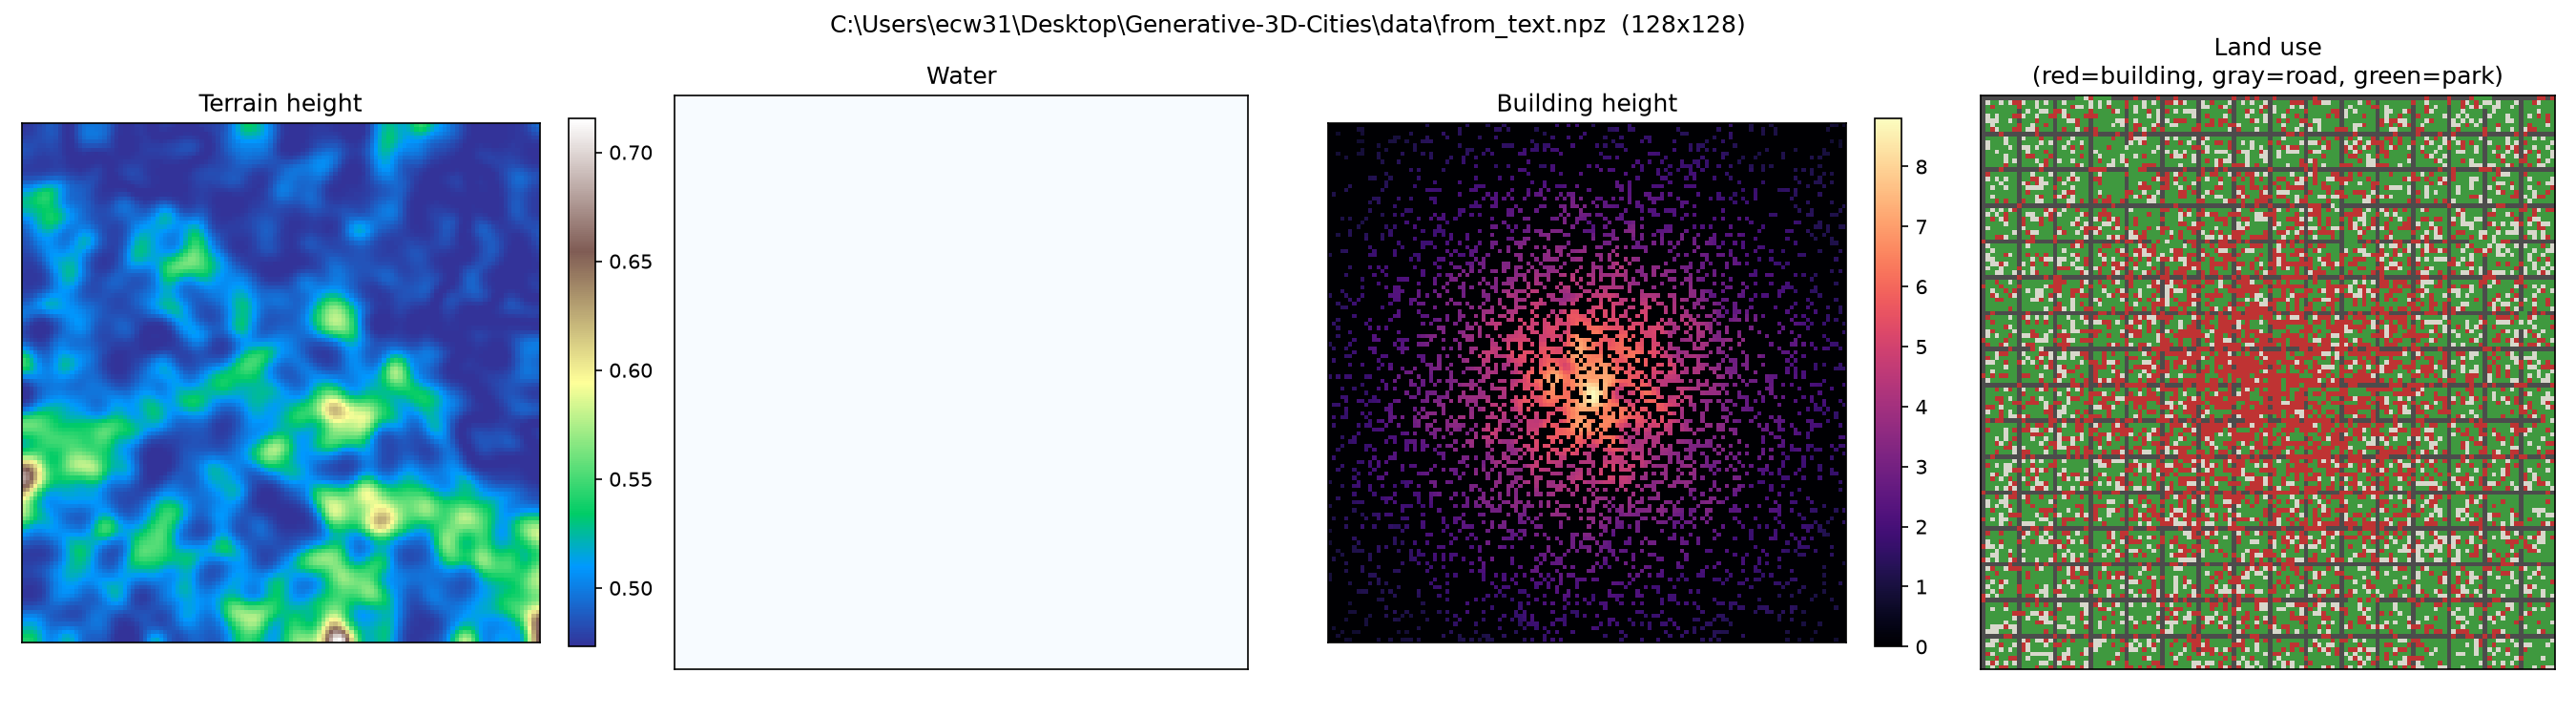

In [49]:
PROMPT = "a hilly city with a packed center full of buildings surrounded by lots of parks and green space"   # <- change me

ok, out = run([sys.executable, "text2city/infer.py", PROMPT, "--seed", "7", "--preview"])
check("infer.py ran end to end", ok and "preview:" in out, "Read the error above.")

png = REPO / "data" / "from_text.png"
if ok and png.exists():
    from IPython.display import Image, display
    display(Image(str(png), width=420))

`--dry-run` only prints the command. This runs it from your **home
folder**, not the repo, to prove `infer.py` finds its files from anywhere:

In [50]:
ok, out = run([sys.executable, str(REPO / "text2city" / "infer.py"),
               "a quiet town on flat land", "--dry-run"], cwd=Path.home())
check("works from another folder, and prints a reusable command",
      ok and "python scripts/generate_city.py" in out and "--seed" in out)

$ c:\Users\ecw31\Desktop\Generative-3D-Cities\.venv\Scripts\python.exe C:\Users\ecw31\Desktop\Generative-3D-Cities\text2city\infer.py a quiet town on flat land --dry-run 


Loading weights: 100%|â–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆ| 103/103 [00:00<00:00, 2644.71it/s]
"a quiet town on flat land"

predicted parameters:
  terrain              = flat
  city_archetype       = monocentric
  num_clusters         = 1.011
  density              = 0.123
  cluster_tightness    = 0.52
  relief               = 1.001
  water_level          = 0.202
  green_amount         = 0.137
  green_override       = False
  road_continuity      = 0.688

generate_city.py command:
  python 'scripts\generate_city.py' --terrain flat --city monocentric --clusters 1 --density 0.123 --cluster-tightness 0.52 --relief 1.001 --green-amount 0.137 --road-continuity 0.688 --size 128 --seed 4746 --out 'data\from_text.npz'
[FAIL] works from another folder, and prints a reusable command


False

**Try this in a terminal** (repo root, venv active): copy the printed
`python scripts/generate_city.py ...` line, change one number (say
`--density`), add `--out data/tweaked.npz`, run it, then
`python scripts/visualize_2d.py data/tweaked.npz`. You just edited the
model's answer by hand. That's the point of printing the command.

---

## Part 3 — Does the city match the sentence?

Week 5 asked: **does the model predict the right numbers?** Today's
question is different: **does the city that comes out look like the
sentence?** The model can be right and the city still wrong, because the
generator has its own rules (e.g. green space only fills ground left empty
after buildings and roads, unless `green_override` is on).

The test: pairs of sentences that should differ in something **you can
measure on the grid**. First you need the measurement.

In [51]:
def measure_city(npz_path) -> dict:
    """
    What a generated city actually looks like, as fractions:
        water      share of ALL cells that are water
        building   share of LAND cells (not water) with land_use 1
        road       share of LAND cells with land_use 2
        green      share of LAND cells with land_use 3
    """
    data = np.load(npz_path)
    land_use, is_water = data["land_use"], data["is_water"]
    land = ~is_water
    n_land = max(int(land.sum()), 1)
    return {
        "water": float(is_water.mean()),
        # TODO 4: the share of LAND cells with each land_use code
        # (1 = building, 2 = road, 3 = green). (land_use == 1) is a True/False
        # grid; `& land` keeps only land cells; .sum() counts the Trues.
        # Divide by n_land and wrap in float().
        "building": float(((land_use == 1) & land).sum() / n_land),
        "road": float(((land_use == 2) & land).sum() / n_land),
        "green": float(((land_use == 3) & land).sum() / n_land),
    }


# check on a tiny 4x4 city where we know the answer:
# top row water (4 cells) -> 12 land cells: 3 building, 4 road, 2 green, 3 empty
_lu = np.array([[0, 0, 0, 0], [1, 1, 1, 2], [2, 2, 2, 3], [3, 0, 0, 0]], dtype=np.uint8)
_w = np.zeros((4, 4), dtype=bool); _w[0] = True
np.savez(REPO / "data" / "_measure_test.npz", land_use=_lu, is_water=_w)
try:
    m = measure_city(REPO / "data" / "_measure_test.npz")
    want = {"water": 0.25, "building": 0.25, "road": 4 / 12, "green": 2 / 12}
    check("TODO 4: measure_city on a known 4x4 grid",
          isinstance(m, dict) and all(isinstance(m.get(k), float) and abs(m[k] - v) < 1e-9 for k, v in want.items()),
          f"want {want}\n  got  {m}\nDivide by n_land (land cells), not by all 16 cells.")
except BaseException as e:
    check("TODO 4 runs", False, f"{type(e).__name__}: {e}")

[PASS] TODO 4: measure_city on a known 4x4 grid


Now the pairs. For each sentence, predict once, build the city with three
seeds (one seed can be a fluke), and average the measurement. Each result
says **which half** to blame when it misses: the model (the predicted
values are backwards) or the generator (the values were right but the
city didn't show it).

In [52]:
PAIRS = [
    # (should have MORE,                            should have LESS,                                measure,    driven by)
    ("an extremely dense city packed with buildings", "a sparse town with only a few scattered buildings", "building", "density"),
    ("a city full of parks and green space",          "a concrete city with almost no greenery",           "green",    "green_amount"),
    ("a city with a complete, well connected street grid", "a city with a broken, patchy street network",  "road",     "road_continuity"),
    ("a huge metropolis with tons of buildings", "a small city without many buildings",                    "building", "density")
    # TODO 5: add ONE pair of your own: (should have MORE, should have LESS,
    # what to measure, which parameter should drive it). Measure is one of
    # "building", "road", "green". Phrase it the way a person would type.
]

inf = fresh("text2city.infer")
schema = importlib.import_module("text2city.schema")
sys.path.insert(0, str(REPO / "scripts"))
sys.modules.pop("generate_city", None)
from generate_city import build_city

check("TODO 5: at least one pair of your own (4+ pairs)", len(PAIRS) >= 4, f"found {len(PAIRS)}")
check("TODO 5: every measure is building / road / green and every parameter exists",
      all(m in ("building", "road", "green") and d in schema.PARAM_BY_NAME for *_, m, d in PAIRS))


def city_from_text(prompt, seeds=(0, 1, 2), size=96):
    """Same steps as infer.py, in-process: predict once, build with each seed, average."""
    params = inf.predict_params(prompt)
    kwargs = schema.to_generator_kwargs(params)
    tmp = REPO / "data" / "_pair.npz"
    results = []
    for s in seeds:
        build_city(size=size, seed=s, **kwargs).save(str(tmp))
        results.append(measure_city(tmp))
    return params, {k: float(np.mean([r[k] for r in results])) for k in results[0]}


hits = 0
try:
    for more, less, measure, driver in PAIRS:
        p_more, m_more = city_from_text(more)
        p_less, m_less = city_from_text(less)
        ok = m_more[measure] > m_less[measure] + 0.01
        hits += ok
        print(f'\n  MORE: "{more}"\n        {driver} = {p_more[driver]}   ->  {measure} {m_more[measure]:.1%}')
        print(f'  LESS: "{less}"\n        {driver} = {p_less[driver]}   ->  {measure} {m_less[measure]:.1%}')
        if ok:
            print("  PASS")
        elif not p_more[driver] > p_less[driver]:
            print(f"  MISS -- the MODEL got it backwards: {driver} wasn't higher for the first sentence")
        else:
            print(f"  MISS -- the model was right, but the GENERATOR didn't show it in the city")
    print(f"\npairs that came out the right way round: {hits}/{len(PAIRS)}")
except BaseException as e:
    check("the pair test runs", False, f"{type(e).__name__}: {e}\nTODO 1 and TODO 4 both have to work for this cell.")

[PASS] TODO 5: at least one pair of your own (4+ pairs)
[PASS] TODO 5: every measure is building / road / green and every parameter exists


Loading weights: 100%|██████████| 103/103 [00:00<00:00, 23656.41it/s]



  MORE: "an extremely dense city packed with buildings"
        density = 0.998   ->  building 32.5%
  LESS: "a sparse town with only a few scattered buildings"
        density = 0.256   ->  building 9.9%
  PASS


Loading weights: 100%|██████████| 103/103 [00:00<00:00, 2828.18it/s]



  MORE: "a city full of parks and green space"
        green_amount = 0.796   ->  green 47.6%
  LESS: "a concrete city with almost no greenery"
        green_amount = 0.033   ->  green 2.1%
  PASS


Loading weights: 100%|██████████| 103/103 [00:00<00:00, 3157.69it/s]



  MORE: "a city with a complete, well connected street grid"
        road_continuity = 0.915   ->  road 27.7%
  LESS: "a city with a broken, patchy street network"
        road_continuity = 0.076   ->  road 0.1%
  PASS


Loading weights: 100%|██████████| 103/103 [00:00<00:00, 3765.02it/s]



  MORE: "a huge metropolis with tons of buildings"
        density = 0.828   ->  building 26.0%
  LESS: "a small city without many buildings"
        density = 0.147   ->  building 5.6%
  PASS

pairs that came out the right way round: 4/4


**A MISS here isn't a bug in your code.** It's a finding. Talk it
through with the people next to you:

1. For each MISS, which half was to blame, the model or the generator?
2. A *generator* miss: what would you change in `buildings.py` to make it
   show up? A *model* miss: what would you add to the phrase banks in
   `generate_dataset.py`?
3. Run the same pair with `green_override` in mind: why could
   *"lots of parks"* still come out with little green in a very dense city?

---

## Part 4 — Blender, and the gallery

Export your favourite prompt from Part 2 (`data/from_text.npz`, so re-run
that cell with your best `PROMPT` first). Same script as Week 3: you get a
`.blend` and a printable `.stl`. No Blender on this laptop? The cell says
SKIP. Do this part on a teammate's laptop.

In [53]:
import shutil


def find_blender():
    exe = shutil.which("blender")
    if exe:
        return exe
    candidates = ["/Applications/Blender.app/Contents/MacOS/Blender",
                  "/usr/bin/blender", "/usr/local/bin/blender", "/snap/bin/blender"]
    candidates += [str(p) for p in Path("/Applications").glob("Blender*/Contents/MacOS/Blender")]
    for base in (r"C:\Program Files\Blender Foundation", r"C:\Program Files (x86)\Blender Foundation"):
        if Path(base).exists():
            candidates += [str(p) for p in Path(base).glob("Blender*/blender.exe")]
    return next((c for c in candidates if Path(c).exists()), None)


BLENDER = find_blender()       # or set it by hand, e.g. "/Applications/Blender.app/Contents/MacOS/Blender"
CITY = REPO / "data" / "from_text.npz"

if not BLENDER:
    print("[SKIP] Blender not found -- set BLENDER above, or export on a teammate's laptop.")
elif not CITY.exists():
    print("[SKIP] no data/from_text.npz yet -- run the 'Run the whole thing' cell in Part 2 first.")
else:
    cmd = [BLENDER, "--background", "--python", str((REPO / "scripts" / "export_to_blender.py").resolve()),
           "--", str(CITY.resolve())]
    print("$", " ".join(cmd))
    p = subprocess.run(cmd, capture_output=True, text=True, timeout=600, cwd=REPO)
    log = (p.stdout or "") + (p.stderr or "")
    print("\n".join(log.strip().splitlines()[-15:]))
    failed = "Traceback" in log or p.returncode != 0
    check(".blend saved", not failed and CITY.with_suffix(".blend").exists(), "Read the log above.")
    check(".stl saved (printable)", CITY.with_suffix(".stl").exists())

$ C:\Program Files\Blender Foundation\Blender 5.2\blender.exe --background --python C:\Users\ecw31\Desktop\Generative-3D-Cities\scripts\export_to_blender.py -- C:\Users\ecw31\Desktop\Generative-3D-Cities\data\from_text.npz
loaded C:\Users\ecw31\Desktop\Generative-3D-Cities\data\from_text.npz
  stats: {'size': 128, 'water_pct': 0.0, 'building_pct': 25.30517578125, 'green_pct': 44.781494140625, 'road_pct': 16.998291015625, 'max_building_height': 8.797429084777832, 'mean_building_height': 3.19881272315979}
Info: Saved as "from_text.blend"
saved C:\Users\ecw31\Desktop\Generative-3D-Cities\data\from_text.blend
Blender 5.2.2 LTS (hash d13f752e3b9c built 2026-09-15 01:37:04)

Blender quit
C:\Users\ecw31\Desktop\Generative-3D-Cities\scripts\export_to_blender.py:60: DeprecationWarning: 'Material.use_nodes' is expected to be removed in Blender 6.0
  mat.use_nodes = True
[PASS] .blend saved
[FAIL] .stl saved (printable)


### Gallery

Open `data/from_text.blend`, frame a nice view, take a screenshot. Add it to
the team's shared gallery slide **with the exact sentence you typed**. This
is what we show at the project fair.

### Checklist

- [ ] 1b: every Week 5 file says `ok`, and the model is retrained
- [ ] Part 2: every `infer.py` check `[PASS]`, including *command-line city == direct city*
- [ ] `python text2city/infer.py "..." --preview` works from a terminal
- [ ] Part 3: one pair of your own, and you know which half to blame for each MISS
- [ ] One prompt exported to Blender, screenshot in the gallery
- [ ] Committed and pushed (`checkpoint/` and `data/` stay out of git)

**Next week:** a small web page in front of `infer.py`. Type a sentence in a
browser, get a city.